# Bước 1: Khai báo các thư viện cần thiết

In [1]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


# Bước 2: Đọc và nạp bộ dữ liệu khối

In [2]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Tải bộ dữ liệu mẫu chọc hút tế bào
cancer = load_breast_cancer()
X = cancer.data  # Các thuộc tính đặc trưng tế bào
y = cancer.target  # Nhãn thực tế: 0 = Ác tính (malignant), 1 = Lành tính (benign)

print(f"Kích thước dữ liệu đặc trưng (X): {X.shape}")
print(f"Tên các lớp nhãn: {cancer.target_names}")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước dữ liệu đặc trưng (X): (569, 30)
Tên các lớp nhãn: ['malignant' 'benign']


# Bước 3: Chuẩn hóa dữ liệu

In [3]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


# Bước 4: Thực hiện thuật toán gom cụm $k$-Means


In [4]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Khởi tạo và huấn luyện k-Means với 2 cụm
kmeans = KMeans(n_clusters=2, init='random', n_init=10, random_state=42)
kmeans.fit(X_scaled)

# Lấy nhãn cụm dự đoán từ k-Means
cluster_labels = kmeans.labels_

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


# Bước 5: So sánh kết quả gom cụm với nhãn thực tế

In [5]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from scipy.stats import mode

# Hàm ánh xạ nhãn cụm k-Means sang nhãn thực tế
def match_labels(cluster_labels, true_labels):
    matched_labels = np.zeros_like(cluster_labels)
    for i in range(2):
        mask = (cluster_labels == i)
        if np.any(mask):
            m = mode(true_labels[mask], keepdims=True)
            matched_labels[mask] = m.mode[0]
    return matched_labels

# Ánh xạ nhãn
aligned_labels = match_labels(cluster_labels, y)

# Tính độ chính xác (Accuracy)
acc = accuracy_score(y, aligned_labels)
print(f"Độ chính xác phân loại của k-Means so với thực tế: {acc * 100:.2f}%\n")

# In báo cáo chi tiết
print("Classification Report:")
print(classification_report(y, aligned_labels, target_names=cancer.target_names))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Độ chính xác phân loại của k-Means so với thực tế: 90.51%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.83      0.87       212
      benign       0.90      0.95      0.93       357

    accuracy                           0.91       569
   macro avg       0.91      0.89      0.90       569
weighted avg       0.91      0.91      0.90       569



# Bước 6: Biểu diễn Confusion Matrix bằng Heatmap

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


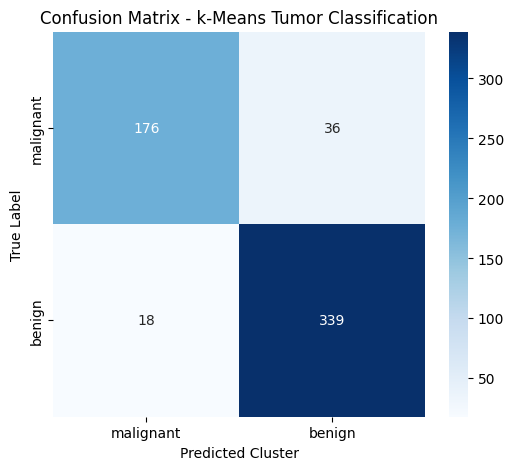

In [6]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

cm = confusion_matrix(y, aligned_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names,
            yticklabels=cancer.target_names)
plt.title('Confusion Matrix - k-Means Tumor Classification')
plt.xlabel('Predicted Cluster')
plt.ylabel('True Label')
plt.show()